# v7 — Nível Tático: Despacho Dinâmico com Falhas

**Nível 3 do sistema de 4 níveis:**

| Nível | Notebook | Problema |
|-------|----------|---------|
| 0 — Topologia | v7_topologia.ipynb | G_nav: barreiras, cachoeiras |
| 1 — Estratégico | v7_quantum_walk.ipynb | QWOA: quais bases ativar |
| 2 — Roteamento | v7_roteamento.ipynb | PC-TSP: rota ótima por drone |
| **3 — Tático** | **este** | **Despacho dinâmico por janela temporal** |

## Problema

Dado o conjunto de bases PEF ativas (do nível estratégico), a cada janela temporal $t$:

1. **Falhas** podem desabilitar drones (aleatório, adversarial, jamming de área).
2. **Urgência** dos microfones evolui: $u_m(t+1) = \min(1,\; u_m(t) + \Delta u)$ se não coletado.
3. **Despacho tático**: selecionar o subconjunto mínimo de drones operacionais que cobre todas as zonas de fronteira alcançáveis, maximizando urgência coletada.

## Hamiltoniano Tático (PLANO_V7.md §5)

$$H_c = \sum_i c_i x_i + \lambda_z \sum_j \left(1 - \sum_i A_{ij}^{(t)} x_i\right)^2 + \lambda_m \sum_m u_m(t)\left(1 - \sum_i R_{im} x_i\right)^2$$

- $A_{ij}^{(t)}$: drone $i$ cobre zona $j$ na janela $t$ (0 se falhou)
- $R_{im}$: drone $i$ pode coletar mic $m$ (dentro do RANGE_KM)
- $u_m(t)$: urgência do mic $m$ (0–1, cresce a cada janela sem coleta)

## Modos de falha

| Modo | Descrição |
|------|-----------|
| `none` | Sem falhas (baseline) |
| `random_drone` | Cada drone falha com $P=0.15$ por janela |
| `targeted_best` | Adversário desabilita o drone de maior cobertura |
| `area_jam` | Jamming desabilita drones dentro de raio geográfico |

## Algoritmos de despacho comparados

| Algoritmo | Tipo |
|-----------|------|
| Greedy urgência-ponderado | Determinístico |
| Walk Iterativo α=0 | Quântico-clássico |
| Walk Iterativo α=2 | Quântico-clássico + potencial de grau |

In [1]:
# =============================================================
# Cell 1 — Imports e parâmetros globais
# =============================================================
import math
import json
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as onp
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"

# --- Parâmetros do problema (idênticos ao roteamento) ---
RANGE_KM           = 200
N_MIC_TOTAL        = 30
N_FRONTIER_SAMPLES = 40
SEED               = 42
FRONTIER_OFFSET    = 24
MIC_OFFSET         = 64

# --- Parâmetros táticos ---
T_WINDOWS     = 10          # janelas temporais (sorties)
DELTA_U       = 0.12        # incremento de urgência por janela sem coleta
P_DRONE_FAIL  = 0.15        # probabilidade de falha aleatória por drone/janela
JAM_RADIUS_KM = 350.0       # raio do jamming geográfico
TARGET_KILL   = 1           # número de drones a matar no modo targeted
LAM_Z         = 20.0        # peso de penalidade por zona não coberta
LAM_M         = 10.0        # peso de penalidade por mic urgente não coletado
N_WALK_RUNS   = 50          # runs do walk iterativo por janela

STRATEGIC_ALG = "walk_a0"   # solução estratégica: "greedy", "walk_a0", "walk_a2"
FAIL_MODES    = ["none", "random_drone", "targeted_best", "area_jam"]
DISPATCH_ALGS = ["greedy", "walk_a0", "walk_a2"]

print(f"T_WINDOWS     = {T_WINDOWS}")
print(f"DELTA_U       = {DELTA_U}  (urgência +{DELTA_U}/janela sem coleta)")
print(f"P_DRONE_FAIL  = {P_DRONE_FAIL}")
print(f"N_WALK_RUNS   = {N_WALK_RUNS}")
print(f"STRATEGIC_ALG = {STRATEGIC_ALG}")

T_WINDOWS     = 10
DELTA_U       = 0.12  (urgência +0.12/janela sem coleta)
P_DRONE_FAIL  = 0.15
N_WALK_RUNS   = 50
STRATEGIC_ALG = walk_a0


In [2]:
# =============================================================
# Cell 2 — Reproduzir dados base (idêntico ao roteamento, SEED=42)
# =============================================================
onp.random.seed(SEED)

df         = pd.read_excel(DATA_DIR / "pef_planilha.xlsx")
base_lats  = df["latitude"].values.astype(float)
base_lons  = df["longitude"].values.astype(float)
base_names = df["localidade"].values.tolist()

# Polilinha da fronteira (mesma lógica do roteamento)
sort_idx = onp.argsort(base_lons)
s_lats   = base_lats[sort_idx]
s_lons   = base_lons[sort_idx]

def _seg_dist_km(la1, lo1, la2, lo2):
    R = 6371.0
    d = onp.radians([la2 - la1, lo2 - lo1])
    a = (onp.sin(d[0]/2)**2
         + onp.cos(onp.radians(la1)) * onp.cos(onp.radians(la2))
         * onp.sin(d[1]/2)**2)
    return 2.0 * R * onp.arcsin(onp.sqrt(a))

cum_len = onp.zeros(len(s_lats))
for k in range(1, len(s_lats)):
    cum_len[k] = cum_len[k-1] + _seg_dist_km(
        s_lats[k-1], s_lons[k-1], s_lats[k], s_lons[k])
total_len = cum_len[-1]

sample_dists  = onp.linspace(0.0, total_len, N_FRONTIER_SAMPLES)
frontier_lats = onp.zeros(N_FRONTIER_SAMPLES)
frontier_lons = onp.zeros(N_FRONTIER_SAMPLES)
for idx, sd in enumerate(sample_dists):
    seg_i = int(onp.searchsorted(cum_len, sd, side="right")) - 1
    seg_i = min(seg_i, len(s_lats) - 2)
    span  = cum_len[seg_i + 1] - cum_len[seg_i]
    t_frac = (sd - cum_len[seg_i]) / (span + 1e-12)
    frontier_lats[idx] = s_lats[seg_i] + t_frac * (s_lats[seg_i+1] - s_lats[seg_i])
    frontier_lons[idx] = s_lons[seg_i] + t_frac * (s_lons[seg_i+1] - s_lons[seg_i])

# Microfones (mesma seed → mesmas posições e urgências iniciais)
anchor_idx    = onp.random.randint(0, N_FRONTIER_SAMPLES, N_MIC_TOTAL)
mic_lats      = frontier_lats[anchor_idx] + onp.random.uniform(-0.4, 0.4, N_MIC_TOTAL)
mic_lons      = frontier_lons[anchor_idx] + onp.random.uniform(-0.4, 0.4, N_MIC_TOTAL)
mic_urgency_0 = onp.random.uniform(0.1, 1.0, N_MIC_TOTAL)  # urgência inicial t=0

# Matriz de distâncias haversine (94×94)
all_lats = onp.concatenate([base_lats, frontier_lats, mic_lats])
all_lons = onp.concatenate([base_lons, frontier_lons, mic_lons])
dlat  = onp.radians(all_lats[:, None] - all_lats[None, :])
dlon  = onp.radians(all_lons[:, None] - all_lons[None, :])
cos_i = onp.cos(onp.radians(all_lats))
a_mat = onp.clip(
    onp.sin(dlat/2)**2 + cos_i[:,None]*cos_i[None,:]*onp.sin(dlon/2)**2, 0.0, 1.0)
dist_mat = 2.0 * 6371.0 * onp.arcsin(onp.sqrt(a_mat))

print(f"Bases: {len(base_names)} | Fronteira: {N_FRONTIER_SAMPLES} pts | Mics: {N_MIC_TOTAL}")
print(f"dist_mat: {dist_mat.shape}")

Bases: 24 | Fronteira: 40 pts | Mics: 30
dist_mat: (94, 94)


In [3]:
# =============================================================
# Cell 3 — Matrizes táticas A e R a partir dos resultados
# =============================================================

# Carregar resultados estratégicos
with open(DATA_DIR / "v7_strategic_results.json") as f:
    strat = json.load(f)

active_bases = strat[STRATEGIC_ALG]["bases"]  # índices globais (0-23)
n_D          = len(active_bases)               # número de drones ativos

print(f"Solução estratégica: {STRATEGIC_ALG}")
print(f"  k = {n_D} bases ativas")
print(f"  Bases: {[base_names[b] for b in active_bases]}")

# --- A_tac[d, f]: drone d cobre ponto de fronteira f ---
# (shape: n_D × N_FRONTIER_SAMPLES)
A_tac = onp.array([
    [
        1 if dist_mat[active_bases[d], FRONTIER_OFFSET + f] <= RANGE_KM else 0
        for f in range(N_FRONTIER_SAMPLES)
    ]
    for d in range(n_D)
], dtype=int)

# --- R_tac[d, m]: drone d pode coletar microfone m ---
# (shape: n_D × N_MIC_TOTAL)
R_tac = onp.array([
    [
        1 if dist_mat[active_bases[d], MIC_OFFSET + m] <= RANGE_KM else 0
        for m in range(N_MIC_TOTAL)
    ]
    for d in range(n_D)
], dtype=int)

reachable_zones = A_tac.sum(axis=0) > 0   # quais zonas são alcançáveis por algum drone
reachable_mics  = R_tac.sum(axis=0) > 0   # quais mics são alcançáveis

print(f"\nA_tac:  {A_tac.shape}  —  {reachable_zones.sum()}/{N_FRONTIER_SAMPLES} zonas alcançáveis")
print(f"R_tac:  {R_tac.shape}  —  {reachable_mics.sum()}/{N_MIC_TOTAL} mics alcançáveis")
print(f"Cobertura por drone: {A_tac.sum(axis=1).tolist()}")

# Centro geográfico da área de missão (para jamming)
JAM_CENTER_LAT = float(onp.mean(base_lats[active_bases]))
JAM_CENTER_LON = float(onp.mean(base_lons[active_bases]))
print(f"\nCentro do jamming: ({JAM_CENTER_LAT:.2f}°, {JAM_CENTER_LON:.2f}°)")

Solução estratégica: walk_a0
  k = 10 bases ativas
  Bases: ['Surucucu', 'Humaitá', 'Santa Rosa do Purus', 'Uiramutã', 'Cucui', 'Vila Bittencourt', 'Palmeira do Javari', 'Cruzeiro do Sul', 'Plácido de Castro', 'Pimenteiras do Oeste']

A_tac:  (10, 40)  —  21/40 zonas alcançáveis
R_tac:  (10, 30)  —  17/30 mics alcançáveis
Cobertura por drone: [2, 3, 2, 2, 2, 3, 3, 2, 1, 1]

Centro do jamming: (-4.49°, -66.43°)


In [4]:
# =============================================================
# Cell 4 — Modelos de falha
# =============================================================

def apply_failures(available_mask, mode, t, rng):
    """Aplica modelo de falha sobre os drones disponíveis.

    Parâmetros
    ----------
    available_mask : ndarray bool (n_D,) — True = operacional antes da falha
    mode           : str — 'none', 'random_drone', 'targeted_best', 'area_jam'
    t              : int — janela temporal atual
    rng            : np.random.RandomState

    Retorna
    -------
    eff_mask  : ndarray bool (n_D,) — True = operacional após falha
    info      : dict — detalhes da falha
    """
    eff_mask = available_mask.copy()
    info     = {"mode": mode, "killed": [], "jam_active": False}

    if mode == "none":
        return eff_mask, info

    if mode == "random_drone":
        for d in range(n_D):
            if eff_mask[d] and rng.random() < P_DRONE_FAIL:
                eff_mask[d] = False
                info["killed"].append(d)
        return eff_mask, info

    if mode == "targeted_best":
        # Adversário mata os TARGET_KILL drones com maior cobertura de zonas
        coverage = onp.array([
            int(A_tac[d].sum()) if eff_mask[d] else -1
            for d in range(n_D)
        ])
        targets = list(onp.argsort(coverage)[::-1][:TARGET_KILL])
        for d in targets:
            if eff_mask[d] and coverage[d] > 0:
                eff_mask[d] = False
                info["killed"].append(int(d))
        return eff_mask, info

    if mode == "area_jam":
        # Jamming geográfico: desabilita drones dentro de JAM_RADIUS_KM
        info["jam_active"] = True
        R     = 6371.0
        dla   = onp.radians(base_lats[active_bases] - JAM_CENTER_LAT)
        dlo   = onp.radians(base_lons[active_bases] - JAM_CENTER_LON)
        cos_c = onp.cos(onp.radians(JAM_CENTER_LAT))
        cos_b = onp.cos(onp.radians(base_lats[active_bases]))
        a_j   = onp.sin(dla/2)**2 + cos_c * cos_b * onp.sin(dlo/2)**2
        a_j   = onp.clip(a_j, 0.0, 1.0)
        d_jam = 2.0 * R * onp.arcsin(onp.sqrt(a_j))
        for d in range(n_D):
            if eff_mask[d] and d_jam[d] <= JAM_RADIUS_KM:
                eff_mask[d] = False
                info["killed"].append(d)
        return eff_mask, info

    raise ValueError(f"Modo desconhecido: {mode}")


# Teste rápido
rng_test = onp.random.RandomState(0)
avail    = onp.ones(n_D, dtype=bool)
for mode in FAIL_MODES:
    m, info = apply_failures(avail.copy(), mode, 0, rng_test)
    print(f"  {mode:16s}: {m.sum()}/{n_D} op.  killed={info['killed']}")

  none            : 10/10 op.  killed=[]
  random_drone    : 10/10 op.  killed=[]
  targeted_best   : 9/10 op.  killed=[5]
  area_jam        : 10/10 op.  killed=[]


In [5]:
# =============================================================
# Cell 5 — Walk Iterativo urgência-ponderado (despacho tático)
# =============================================================

def _build_tactic_hamiltonian(avail_drones, eff_A, eff_R, urgency, alpha=0.0):
    """Hamiltoniano bipartido ponderado para despacho tático.

    Left : drones disponíveis (n_d)
    Right: zonas de fronteira + mics  (n_z + n_m)

    W[d, z] = 1   para zona z coberta pelo drone d
    W[d, m] = u_m para mic m alcançável pelo drone d (urgência como peso)
    """
    n_d  = len(avail_drones)
    n_z  = eff_A.shape[1]
    n_m  = eff_R.shape[1]
    N    = n_d + n_z + n_m

    W = onp.zeros((n_d, n_z + n_m))
    for di in range(n_d):
        W[di, :n_z] = eff_A[di]
        W[di, n_z:] = eff_R[di] * urgency

    norm = onp.linalg.norm(W)
    if norm > 1e-10:
        W /= norm

    H = onp.zeros((N, N))
    H[:n_d, n_d:] = W
    H[n_d:, :n_d] = W.T

    if alpha > 0.0 and n_d > 0:
        deg  = W.sum(axis=1)
        dmax = deg.max()
        if dmax > 1e-10:
            for di in range(n_d):
                H[di, di] = -alpha * deg[di] / dmax
    return H


def _find_tau(H, n_d):
    """τ* que maximiza concentração de amplitude nos drones (100 pontos)."""
    N            = H.shape[0]
    eigvals, V   = onp.linalg.eigh(H)
    psi0         = onp.zeros(N, dtype=complex)
    psi0[:n_d]   = 1.0 / onp.sqrt(n_d)
    Vdag_psi0    = V.conj().T @ psi0

    best_tau, best_score, best_p = 1.0, -1.0, None
    for tau in onp.linspace(0.1, 30.0, 100):
        psi_t = V @ (onp.exp(-1j * eigvals * tau) * Vdag_psi0)
        p     = onp.abs(psi_t[:n_d]) ** 2
        score = onp.std(p) * onp.sum(p)
        if score > best_score:
            best_score, best_tau, best_p = score, tau, p.copy()
    return best_tau, best_p


def walk_tactic_dispatch(eff_mask, eff_A, eff_R, urgency,
                         alpha=0.0, n_runs=50, seed=0):
    """Walk Iterativo para despacho tático.

    Parâmetros
    ----------
    eff_mask : bool (n_D,) — drones operacionais após falhas
    eff_A    : int (n_D, n_zones) — cobertura efetiva (0 se falhou)
    eff_R    : int (n_D, n_mics)  — alcance de mic (0 se falhou)
    urgency  : float (n_mics,)    — urgência atual de cada mic
    alpha    : float              — potencial de grau

    Retorna
    -------
    best_sel      : list[int] — índices locais dos drones despachados
    zone_cov_rate : float     — fração de zonas alcançáveis cobertas
    """
    avail = [d for d in range(n_D) if eff_mask[d]]
    if not avail:
        return [], 0.0

    n_z   = eff_A.shape[1]
    reach = eff_A[avail].sum(axis=0) > 0

    rng      = onp.random.RandomState(seed)
    best_sel = avail[:]
    best_k   = len(avail) + 1

    for _ in range(n_runs):
        remaining = avail[:]
        covered_z = onp.zeros(n_z, dtype=bool)
        selected  = []

        for _ in range(len(avail)):
            if covered_z[reach].all():
                break
            uncov_z  = [z for z in range(n_z) if not covered_z[z] and reach[z]]
            active_d = [d for d in remaining
                        if onp.any(eff_A[d, uncov_z] == 1)]
            if not active_d:
                break

            n_d_sub = len(active_d)
            if n_d_sub == 1:
                chosen_local = 0
            else:
                A_sub = eff_A[onp.ix_(active_d, uncov_z)]
                R_sub = eff_R[active_d]
                H     = _build_tactic_hamiltonian(
                    active_d, A_sub, R_sub, urgency, alpha=alpha)
                _, probs = _find_tau(H, n_d_sub)
                probs    = probs / probs.sum()
                chosen_local = rng.choice(n_d_sub, p=probs)

            chosen = active_d[chosen_local]
            selected.append(chosen)
            remaining.remove(chosen)
            covered_z |= (eff_A[chosen] == 1)

        if len(selected) < best_k:
            best_k   = len(selected)
            best_sel = selected[:]

    cov_z = onp.zeros(n_z, dtype=bool)
    for d in best_sel:
        cov_z |= (eff_A[d] == 1)
    zone_cov_rate = float(cov_z[reach].mean()) if reach.any() else 1.0

    return best_sel, zone_cov_rate


print("Walk tático definido.")

Walk tático definido.


In [6]:
# =============================================================
# Cell 6 — Greedy tático urgência-ponderado
# =============================================================

def greedy_tactic_dispatch(eff_mask, eff_A, eff_R, urgency):
    """Despacho tático greedy.

    Seleção iterativa: escolhe o drone com maior ganho ponderado
    (zonas cobertas + urgência de mics coletados).

    Retorna
    -------
    selected     : list[int] — índices locais dos drones despachados
    zone_cov_rate: float     — fração de zonas alcançáveis cobertas
    """
    avail     = [d for d in range(n_D) if eff_mask[d]]
    if not avail:
        return [], 0.0

    n_z       = eff_A.shape[1]
    reach     = eff_A[avail].sum(axis=0) > 0
    covered_z = onp.zeros(n_z, dtype=bool)
    selected  = []

    while not covered_z[reach].all():
        uncov_z = ~covered_z & reach
        best_d, best_score = -1, -1.0
        for d in avail:
            if d in selected:
                continue
            # Ganho: zonas novas cobertas (peso LAM_Z) + urgência de mics (peso LAM_M)
            zone_gain = float(onp.sum(eff_A[d] & uncov_z))
            mic_gain  = float(onp.sum(eff_R[d] * urgency))
            score     = LAM_Z * zone_gain + LAM_M * mic_gain
            if score > best_score:
                best_score, best_d = score, d
        if best_d == -1:
            break
        selected.append(best_d)
        covered_z |= (eff_A[best_d] == 1)

    cov_z = onp.zeros(n_z, dtype=bool)
    for d in selected:
        cov_z |= (eff_A[d] == 1)
    zone_cov_rate = float(cov_z[reach].mean()) if reach.any() else 1.0

    return selected, zone_cov_rate


print("Greedy tático definido.")

Greedy tático definido.


In [7]:
# =============================================================
# Cell 7 — Dinâmica de urgência dos microfones
# =============================================================

def step_urgency(urgency, dispatched_drones, eff_R):
    """Atualiza urgência após uma janela temporal.

    - Mics visitados (em rota de algum drone despachado): urgência → 0
    - Mics não visitados: urgência += DELTA_U (clamp a 1)

    Retorna novo vetor de urgência e conjunto de mics coletados.
    """
    collected = onp.zeros(N_MIC_TOTAL, dtype=bool)
    for d in dispatched_drones:
        collected |= (eff_R[d] == 1)

    new_urg = urgency.copy()
    new_urg[collected]  = 0.0                                           # reset
    new_urg[~collected] = onp.minimum(1.0, new_urg[~collected] + DELTA_U)  # crescimento
    return new_urg, collected


def _urgency_stats(urg):
    """Retorna (média, frac_críticos) onde críticos = u > 0.8."""
    return float(urg.mean()), float((urg > 0.8).mean())


print("Dinâmica de urgência definida.")
print(f"  DELTA_U={DELTA_U} → mic cheio em {int(onp.ceil(1.0/DELTA_U))} janelas sem coleta")

Dinâmica de urgência definida.
  DELTA_U=0.12 → mic cheio em 9 janelas sem coleta


In [8]:
# =============================================================
# Cell 8 — Loop de simulação tática
# =============================================================

def run_tactical_sim(fail_mode, dispatch_alg, seed_base=100):
    """Simula T_WINDOWS janelas temporais.

    Parâmetros
    ----------
    fail_mode    : str — 'none', 'random_drone', 'targeted_best', 'area_jam'
    dispatch_alg : str — 'greedy', 'walk_a0', 'walk_a2'
    seed_base    : int — semente para geração de falhas

    Retorna
    -------
    hist : list[dict] — uma entrada por janela temporal
    """
    urgency   = mic_urgency_0.copy()
    hist      = []
    rng       = onp.random.RandomState(seed_base)

    for t in range(T_WINDOWS):
        # 1) Todos os drones estratégicos disponíveis no início da janela
        avail = onp.ones(n_D, dtype=bool)

        # 2) Aplicar falhas
        eff_mask, fail_info = apply_failures(avail, fail_mode, t, rng)
        n_failed   = int((~eff_mask).sum())
        n_oper     = int(eff_mask.sum())

        # 3) Matrizes efetivas (falhos zeramos as linhas)
        eff_A = A_tac.copy().astype(float)
        eff_R = R_tac.copy().astype(float)
        for d in range(n_D):
            if not eff_mask[d]:
                eff_A[d, :] = 0
                eff_R[d, :] = 0
        eff_A = eff_A.astype(int)
        eff_R = eff_R.astype(int)

        # 4) Despacho tático
        if dispatch_alg == "greedy":
            dispatched, zone_cov = greedy_tactic_dispatch(eff_mask, eff_A, eff_R, urgency)
        elif dispatch_alg == "walk_a0":
            dispatched, zone_cov = walk_tactic_dispatch(
                eff_mask, eff_A, eff_R, urgency,
                alpha=0.0, n_runs=N_WALK_RUNS, seed=seed_base + t)
        elif dispatch_alg == "walk_a2":
            dispatched, zone_cov = walk_tactic_dispatch(
                eff_mask, eff_A, eff_R, urgency,
                alpha=2.0, n_runs=N_WALK_RUNS, seed=seed_base + t)
        else:
            raise ValueError(dispatch_alg)

        # 5) Atualizar urgência
        urg_before         = urgency.copy()
        urgency, collected = step_urgency(urgency, dispatched, eff_R)

        # 6) Métricas
        urg_collected = float(urg_before[collected].sum())
        n_crit_before = int((urg_before > 0.8).sum())
        n_crit_after  = int((urgency > 0.8).sum())
        urg_mean, frac_crit = _urgency_stats(urgency)

        hist.append({
            "t"              : t,
            "n_oper"         : n_oper,
            "n_failed"       : n_failed,
            "failed_drones"  : [int(d) for d in range(n_D) if not eff_mask[d]],
            "dispatched"     : [int(d) for d in dispatched],
            "n_dispatched"   : len(dispatched),
            "zone_cov"       : round(zone_cov, 4),
            "mics_collected" : int(collected.sum()),
            "urg_collected"  : round(urg_collected, 4),
            "urg_mean"       : round(urg_mean, 4),
            "frac_crit"      : round(frac_crit, 4),
            "n_crit_resolved": max(0, n_crit_before - n_crit_after),
        })

    return hist


# Teste rápido com greedy/no-failure
print("Teste (greedy, none):")
test_hist = run_tactical_sim("none", "greedy", seed_base=42)
for r in test_hist[:3]:
    print(f"  t={r['t']:2d}  oper={r['n_oper']:2d}  desp={r['n_dispatched']:2d}  "
          f"zone_cov={r['zone_cov']:.3f}  mics={r['mics_collected']:2d}  "
          f"urg_col={r['urg_collected']:.3f}  frac_crit={r['frac_crit']:.3f}")
print("  ...")

Teste (greedy, none):
  t= 0  oper=10  desp=10  zone_cov=1.000  mics=17  urg_col=8.863  frac_crit=0.133
  t= 1  oper=10  desp=10  zone_cov=1.000  mics=17  urg_col=0.000  frac_crit=0.167
  t= 2  oper=10  desp=10  zone_cov=1.000  mics=17  urg_col=0.000  frac_crit=0.267
  ...


In [9]:
# =============================================================
# Cell 9 — Simulação completa: todas combinações (fail_mode × dispatch_alg)
# =============================================================
import time

all_results = {}   # {(fail_mode, dispatch_alg): hist}

for fail_mode in FAIL_MODES:
    for dispatch_alg in DISPATCH_ALGS:
        key = (fail_mode, dispatch_alg)
        t0  = time.time()
        hist = run_tactical_sim(fail_mode, dispatch_alg, seed_base=42)
        dt   = time.time() - t0

        avg_zone_cov = onp.mean([h["zone_cov"] for h in hist])
        total_urg    = sum(h["urg_collected"] for h in hist)
        total_mics   = sum(h["mics_collected"] for h in hist)
        avg_failed   = onp.mean([h["n_failed"] for h in hist])

        all_results[key] = hist
        print(f"  {fail_mode:16s} × {dispatch_alg:8s}  "
              f"zone_cov={avg_zone_cov:.3f}  "
              f"urg={total_urg:.2f}  "
              f"mics={total_mics:3d}  "
              f"avg_failed={avg_failed:.1f}  "
              f"[{dt:.1f}s]")

  none             × greedy    zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [0.0s]


  none             × walk_a0   zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [12.3s]


  none             × walk_a2   zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [12.4s]
  random_drone     × greedy    zone_cov=1.000  urg=12.10  mics=141  avg_failed=1.9  [0.0s]


  random_drone     × walk_a0   zone_cov=1.000  urg=12.10  mics=141  avg_failed=1.9  [9.7s]


  random_drone     × walk_a2   zone_cov=1.000  urg=12.10  mics=141  avg_failed=1.9  [9.7s]
  targeted_best    × greedy    zone_cov=1.000  urg=8.86  mics=170  avg_failed=1.0  [0.0s]


  targeted_best    × walk_a0   zone_cov=1.000  urg=8.86  mics=170  avg_failed=1.0  [10.9s]


  targeted_best    × walk_a2   zone_cov=1.000  urg=8.86  mics=170  avg_failed=1.0  [10.9s]
  area_jam         × greedy    zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [0.0s]


  area_jam         × walk_a0   zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [12.4s]


  area_jam         × walk_a2   zone_cov=1.000  urg=8.86  mics=170  avg_failed=0.0  [12.6s]


In [10]:
# =============================================================
# Cell 10 — Tabela de comparação
# =============================================================

W = 88
print("=" * W)
print(f"RESUMO TÁTICO — {T_WINDOWS} janelas, estratégia: {STRATEGIC_ALG}, "
      f"k={n_D} drones")
print("=" * W)
hdr = (f"{'Falha':<16s}  {'Despacho':<10s}  {'Cob.zona':>8s}  "
       f"{'Urg.colet':>9s}  {'Mics':>4s}  {'Crit.res':>8s}  "
       f"{'Avg fail':>8s}  {'Frac.crit':>9s}")
print(hdr)
print("-" * W)

for fail_mode in FAIL_MODES:
    for dispatch_alg in DISPATCH_ALGS:
        hist         = all_results[(fail_mode, dispatch_alg)]
        avg_zone_cov = onp.mean([h["zone_cov"] for h in hist])
        total_urg    = sum(h["urg_collected"] for h in hist)
        total_mics   = sum(h["mics_collected"] for h in hist)
        total_crit_r = sum(h["n_crit_resolved"] for h in hist)
        avg_failed   = onp.mean([h["n_failed"] for h in hist])
        avg_frac_crit= onp.mean([h["frac_crit"] for h in hist])

        print(
            f"{fail_mode:<16s}  {dispatch_alg:<10s}  "
            f"{avg_zone_cov:>8.3f}  "
            f"{total_urg:>9.2f}  "
            f"{total_mics:>4d}  "
            f"{total_crit_r:>8d}  "
            f"{avg_failed:>8.1f}  "
            f"{avg_frac_crit:>9.3f}"
        )
    print("-" * W)

print("=" * W)
print("Cob.zona  = fração média de zonas alcançáveis cobertas por janela")
print("Urg.colet = urgência total coletada ao longo de todas as janelas")
print("Mics      = microfones coletados (total das 10 janelas)")
print("Crit.res  = microfones críticos (u>0.8) resolvidos")
print("Frac.crit = fração média de mics críticos ao longo do tempo")

RESUMO TÁTICO — 10 janelas, estratégia: walk_a0, k=10 drones
Falha             Despacho    Cob.zona  Urg.colet  Mics  Crit.res  Avg fail  Frac.crit
----------------------------------------------------------------------------------------
none              greedy         1.000       8.86   170         0       0.0      0.347
none              walk_a0        1.000       8.86   170         0       0.0      0.347
none              walk_a2        1.000       8.86   170         0       0.0      0.347
----------------------------------------------------------------------------------------
random_drone      greedy         1.000      12.10   141         0       1.9      0.350
random_drone      walk_a0        1.000      12.10   141         0       1.9      0.350
random_drone      walk_a2        1.000      12.10   141         0       1.9      0.350
----------------------------------------------------------------------------------------
targeted_best     greedy         1.000       8.86   170        

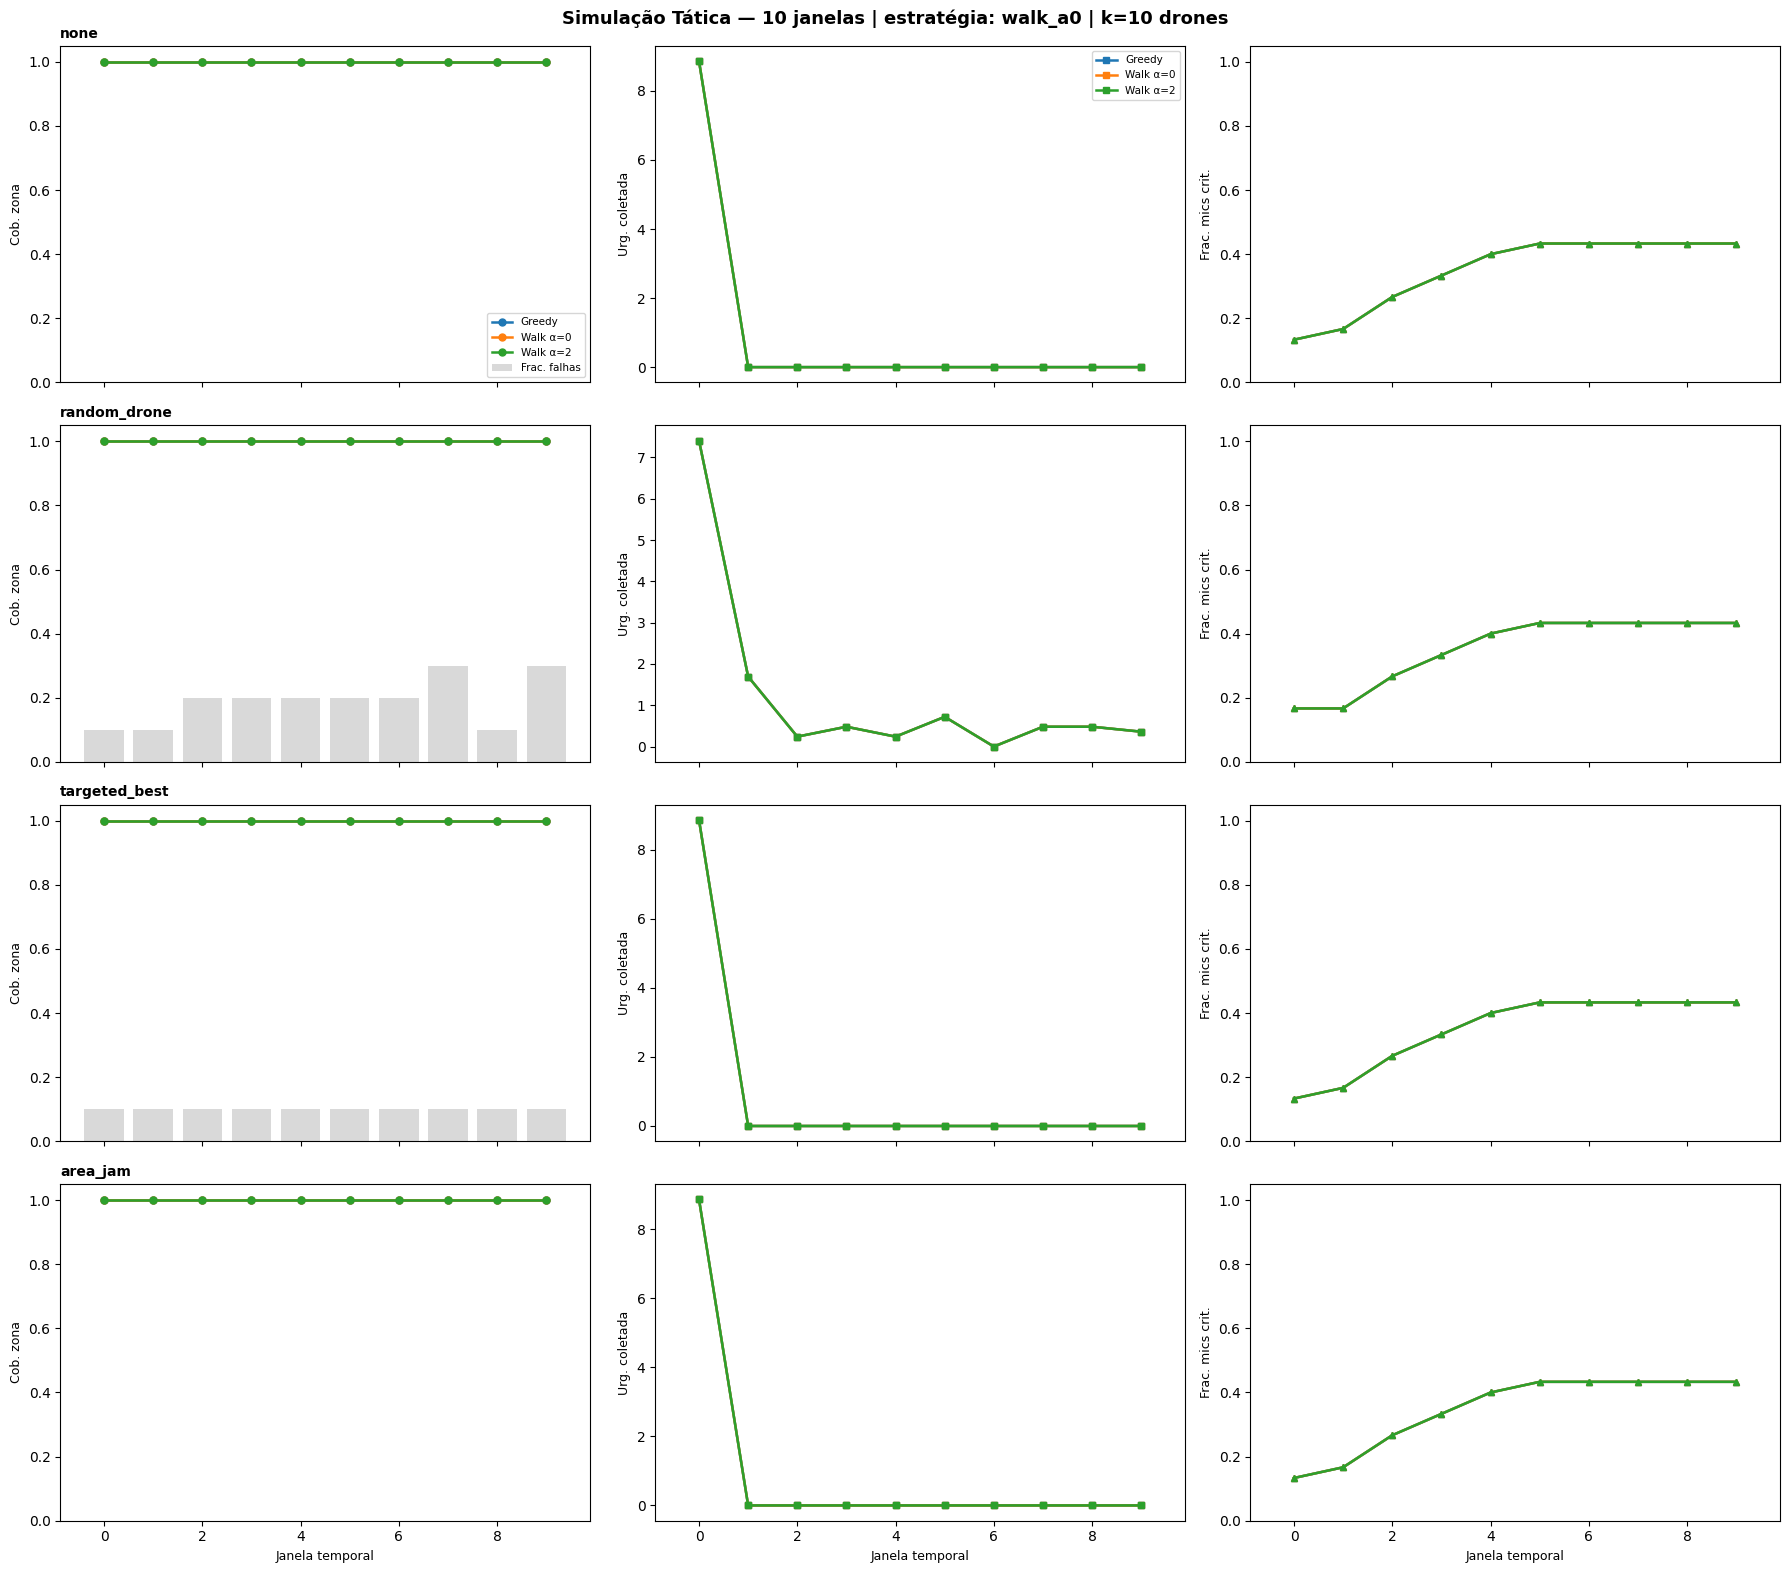

Figura salva em v7_tatico_timeline.png


In [11]:
# =============================================================
# Cell 11 — Visualização: timeline por modo de falha
# =============================================================

colors_alg = {"greedy": "C0", "walk_a0": "C1", "walk_a2": "C2"}
label_alg  = {"greedy": "Greedy", "walk_a0": "Walk α=0", "walk_a2": "Walk α=2"}

fig, axes = plt.subplots(len(FAIL_MODES), 3, figsize=(18, 4 * len(FAIL_MODES)),
                         sharex=True)
fig.suptitle(
    f"Simulação Tática — {T_WINDOWS} janelas | estratégia: {STRATEGIC_ALG} "
    f"| k={n_D} drones",
    fontsize=13, fontweight="bold"
)

for row, fail_mode in enumerate(FAIL_MODES):
    ax_cov, ax_urg, ax_crit = axes[row]

    for dispatch_alg in DISPATCH_ALGS:
        hist  = all_results[(fail_mode, dispatch_alg)]
        ts    = [h["t"] for h in hist]
        color = colors_alg[dispatch_alg]
        lbl   = label_alg[dispatch_alg]

        ax_cov.plot(ts,  [h["zone_cov"] for h in hist],
                    color=color, lw=1.8, marker="o", ms=5, label=lbl)
        ax_urg.plot(ts,  [h["urg_collected"] for h in hist],
                    color=color, lw=1.8, marker="s", ms=5, label=lbl)
        ax_crit.plot(ts, [h["frac_crit"] for h in hist],
                     color=color, lw=1.8, marker="^", ms=5, label=lbl)

    # Número médio de falhas como barra cinza de fundo
    n_failed_list = [onp.mean([all_results[(fail_mode, da)][t]["n_failed"]
                               for da in DISPATCH_ALGS])
                     for t in range(T_WINDOWS)]
    ax_cov.bar(range(T_WINDOWS), [f / n_D for f in n_failed_list],
               color="0.85", zorder=0, label="Frac. falhas")

    ax_cov.set_ylabel("Cob. zona", fontsize=9)
    ax_urg.set_ylabel("Urg. coletada", fontsize=9)
    ax_crit.set_ylabel("Frac. mics crit.", fontsize=9)

    ax_cov.set_title(f"{fail_mode}", fontsize=10, fontweight="bold", loc="left")
    ax_cov.set_ylim(0, 1.05)
    ax_crit.set_ylim(0, 1.05)

    if row == 0:
        ax_cov.legend(fontsize=7.5, loc="lower right")
        ax_urg.legend(fontsize=7.5, loc="upper right")

for ax in axes[-1]:
    ax.set_xlabel("Janela temporal", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "v7_tatico_timeline.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva em v7_tatico_timeline.png")

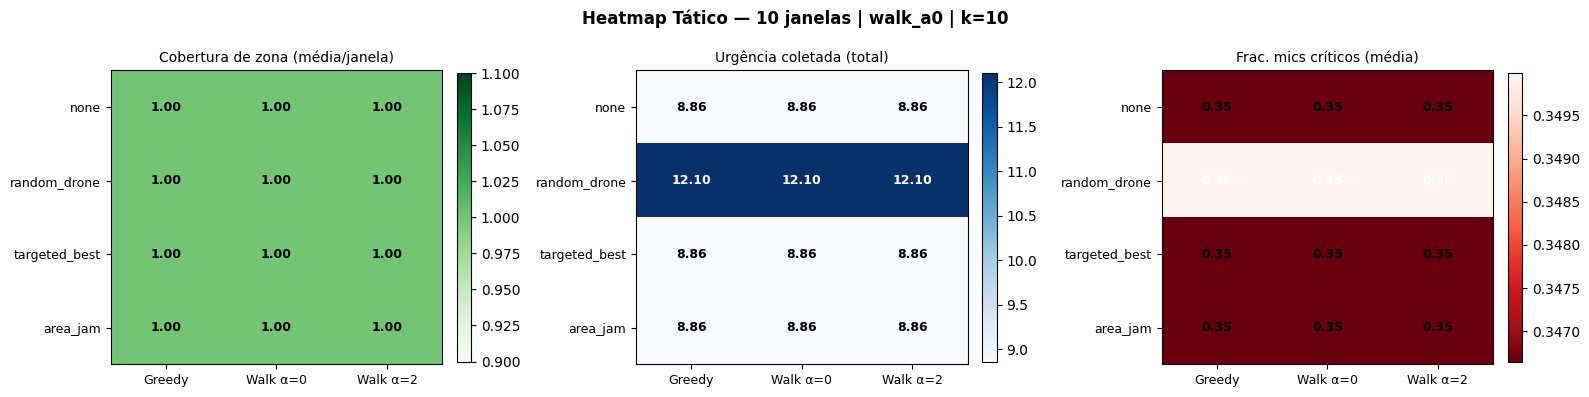

Figura salva em v7_tatico_heatmap.png


In [12]:
# =============================================================
# Cell 12 — Mapa de calor: cobertura × falha × algoritmo
# =============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = ["zone_cov", "urg_collected", "frac_crit"]
titles  = ["Cobertura de zona (média/janela)",
           "Urgência coletada (total)",
           "Frac. mics críticos (média)"]
cmaps   = ["Greens", "Blues", "Reds_r"]

for ax, metric, title, cmap in zip(axes, metrics, titles, cmaps):
    data = onp.zeros((len(FAIL_MODES), len(DISPATCH_ALGS)))
    for i, fm in enumerate(FAIL_MODES):
        for j, da in enumerate(DISPATCH_ALGS):
            hist = all_results[(fm, da)]
            if metric == "urg_collected":
                data[i, j] = sum(h[metric] for h in hist)
            else:
                data[i, j] = onp.mean([h[metric] for h in hist])

    im = ax.imshow(data, cmap=cmap, aspect="auto",
                   vmin=data.min(), vmax=data.max())
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04)

    ax.set_xticks(range(len(DISPATCH_ALGS)))
    ax.set_xticklabels(["Greedy", "Walk α=0", "Walk α=2"], fontsize=9)
    ax.set_yticks(range(len(FAIL_MODES)))
    ax.set_yticklabels(FAIL_MODES, fontsize=9)
    ax.set_title(title, fontsize=10)

    for i in range(len(FAIL_MODES)):
        for j in range(len(DISPATCH_ALGS)):
            ax.text(j, i, f"{data[i, j]:.2f}",
                    ha="center", va="center", fontsize=9, fontweight="bold",
                    color="white" if data[i, j] > data.mean() else "black")

fig.suptitle(
    f"Heatmap Tático — {T_WINDOWS} janelas | {STRATEGIC_ALG} | k={n_D}",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "v7_tatico_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva em v7_tatico_heatmap.png")

In [13]:
# =============================================================
# Cell 13 — Exportação JSON
# =============================================================

export = {
    "config": {
        "strategic_alg" : STRATEGIC_ALG,
        "active_bases"  : active_bases,
        "k"             : n_D,
        "T_windows"     : T_WINDOWS,
        "delta_u"       : DELTA_U,
        "p_drone_fail"  : P_DRONE_FAIL,
        "jam_radius_km" : JAM_RADIUS_KM,
        "RANGE_KM"      : RANGE_KM,
    },
    "results": {}
}

for (fail_mode, dispatch_alg), hist in all_results.items():
    key = f"{fail_mode}__{dispatch_alg}"
    export["results"][key] = {
        "fail_mode"      : fail_mode,
        "dispatch_alg"   : dispatch_alg,
        "avg_zone_cov"   : float(onp.mean([h["zone_cov"] for h in hist])),
        "total_urg"      : float(sum(h["urg_collected"] for h in hist)),
        "total_mics"     : int(sum(h["mics_collected"] for h in hist)),
        "total_crit_res" : int(sum(h["n_crit_resolved"] for h in hist)),
        "avg_frac_crit"  : float(onp.mean([h["frac_crit"] for h in hist])),
        "history"        : hist,
    }

with open(RESULTS_DIR / "v7_tatico_results.json", "w") as f:
    json.dump(export, f, indent=2)

print("Exportado para v7_tatico_results.json")
print(f"  Combinações: {len(all_results)}  ({len(FAIL_MODES)} modos × {len(DISPATCH_ALGS)} algs)")

# Sumário final
print("\n=== ACHADOS PRINCIPAIS ===")
for fm in FAIL_MODES:
    best_alg = max(DISPATCH_ALGS,
                   key=lambda da: sum(all_results[(fm, da)][t]["zone_cov"]
                                      for t in range(T_WINDOWS)))
    best_cov = onp.mean([all_results[(fm, best_alg)][t]["zone_cov"]
                         for t in range(T_WINDOWS)])
    best_urg = sum(all_results[(fm, best_alg)][t]["urg_collected"]
                   for t in range(T_WINDOWS))
    print(f"  {fm:16s}: melhor despacho = {best_alg:8s}  "
          f"cov={best_cov:.3f}  urg={best_urg:.2f}")

Exportado para v7_tatico_results.json
  Combinações: 12  (4 modos × 3 algs)

=== ACHADOS PRINCIPAIS ===
  none            : melhor despacho = greedy    cov=1.000  urg=8.86
  random_drone    : melhor despacho = greedy    cov=1.000  urg=12.10
  targeted_best   : melhor despacho = greedy    cov=1.000  urg=8.86
  area_jam        : melhor despacho = greedy    cov=1.000  urg=8.86


## Parte A — Over-Provisioning: k=14 vs k=10

### Por que o nível tático foi indiferente até aqui?

Com k=10 (mínimo exato do set cover), **todos os drones são sempre necessários**.
O tático não tem margem de escolha: qualquer falha derruba alguma zona.

### Solução: Over-Provisioning

Ativar **k=14** bases (10 originais + 4 bases redundantes de maior cobertura).
O tático pode agora:
- Usar **~10 drones** numa janela normal, poupando 4 de bateria
- Recorrer às reservas quando drones falharem

### Experimentos

| Cenário | k | P_fail | Expectativa |
|---------|---|--------|-------------|
| Baseline (Parte 0) | 10 | 0.15 | zona_cov=1.0, sem diferenciação |
| Over-prov (P leve) | 14 | 0.15 | zona_cov=1.0, Walk ≠ Greedy em economia |
| Over-prov (P severo) | 14 | 0.40 | zona_cov degradada, Walk > Greedy |
| k_opt (P severo) | 10 | 0.40 | zona_cov colapsa sem reserva |

In [14]:
# =============================================================
# Cell A1 — Configuração over-provisioned (k=14)
# =============================================================

# Bases já ativas no cenário k=10
active_bases_10 = list(active_bases)   # solução walk_a0 original

# Candidatas adicionais: as 14 bases não ativas
remaining_cand = [b for b in range(24) if b not in active_bases_10]

# Seleciona as 4 com maior cobertura de fronteira (redundância máxima)
cov_cand = [
    (b, int((dist_mat[b, FRONTIER_OFFSET:FRONTIER_OFFSET + N_FRONTIER_SAMPLES]
             <= RANGE_KM).sum()))
    for b in remaining_cand
]
cov_cand.sort(key=lambda x: x[1], reverse=True)
extra_bases = [b for b, _ in cov_cand[:4]]

active_bases_14 = active_bases_10 + extra_bases
n_D14 = len(active_bases_14)

print(f"k=10 (mínimo)  : {[base_names[b] for b in active_bases_10]}")
print(f"4 bases extras : {[base_names[b] for b in extra_bases]}")
print(f"  cov: {[c for _, c in cov_cand[:4]]} pontos de fronteira cada")
print(f"k=14 (overprov): {[base_names[b] for b in active_bases_14]}")

# Matrizes para k=14
A_tac14 = onp.array([
    [1 if dist_mat[active_bases_14[d], FRONTIER_OFFSET + f] <= RANGE_KM else 0
     for f in range(N_FRONTIER_SAMPLES)]
    for d in range(n_D14)
], dtype=int)

R_tac14 = onp.array([
    [1 if dist_mat[active_bases_14[d], MIC_OFFSET + m] <= RANGE_KM else 0
     for m in range(N_MIC_TOTAL)]
    for d in range(n_D14)
], dtype=int)

reach14 = A_tac14.sum(axis=0) > 0
print(f"\nA_tac14: {A_tac14.shape}  —  {reach14.sum()}/{N_FRONTIER_SAMPLES} zonas alcançáveis")
print(f"R_tac14: {R_tac14.shape}  —  {(R_tac14.sum(axis=0)>0).sum()}/{N_MIC_TOTAL} mics alcançáveis")
print(f"Cobertura por drone: {A_tac14.sum(axis=1).tolist()}")

k=10 (mínimo)  : ['Surucucu', 'Humaitá', 'Santa Rosa do Purus', 'Uiramutã', 'Cucui', 'Vila Bittencourt', 'Palmeira do Javari', 'Cruzeiro do Sul', 'Plácido de Castro', 'Pimenteiras do Oeste']
4 bases extras : ['Ipiranga', 'Tabatinga', 'Estirão do Equador', 'Porto Velho']
  cov: [3, 3, 3, 3] pontos de fronteira cada
k=14 (overprov): ['Surucucu', 'Humaitá', 'Santa Rosa do Purus', 'Uiramutã', 'Cucui', 'Vila Bittencourt', 'Palmeira do Javari', 'Cruzeiro do Sul', 'Plácido de Castro', 'Pimenteiras do Oeste', 'Ipiranga', 'Tabatinga', 'Estirão do Equador', 'Porto Velho']

A_tac14: (14, 40)  —  21/40 zonas alcançáveis
R_tac14: (14, 30)  —  19/30 mics alcançáveis
Cobertura por drone: [2, 3, 2, 2, 2, 3, 3, 2, 1, 1, 3, 3, 3, 3]


In [15]:
# =============================================================
# Cell A2 — Simulação paramétrica (n_D, A, R, P_fail configuráveis)
# =============================================================

def run_sim_param(n_D_loc, A_loc, R_loc, active_loc,
                  fail_mode, dispatch_alg,
                  p_fail=0.15, jam_radius=350.0,
                  seed_base=42):
    """Simulação tática totalmente paramétrica.

    Aceita qualquer conjunto de bases (k=10 ou k=14) e qualquer P_fail,
    sem depender de variáveis globais mutáveis.
    """
    # Centro de jamming para este conjunto de bases
    jc_lat = float(onp.mean(base_lats[active_loc]))
    jc_lon = float(onp.mean(base_lons[active_loc]))

    def _apply_fail(mask, mode, t, rng):
        m    = mask.copy()
        info = {"killed": []}
        if mode == "none":
            return m, info
        if mode == "random_drone":
            for d in range(n_D_loc):
                if m[d] and rng.random() < p_fail:
                    m[d] = False; info["killed"].append(d)
            return m, info
        if mode == "targeted_best":
            cov  = onp.array([int(A_loc[d].sum()) if m[d] else -1 for d in range(n_D_loc)])
            tgts = list(onp.argsort(cov)[::-1][:TARGET_KILL])
            for d in tgts:
                if m[d] and cov[d] > 0:
                    m[d] = False; info["killed"].append(int(d))
            return m, info
        if mode == "area_jam":
            R_e   = 6371.0
            dla   = onp.radians(base_lats[active_loc] - jc_lat)
            dlo   = onp.radians(base_lons[active_loc] - jc_lon)
            cos_c = onp.cos(onp.radians(jc_lat))
            cos_b = onp.cos(onp.radians(base_lats[active_loc]))
            a_j   = onp.clip(onp.sin(dla/2)**2 + cos_c * cos_b * onp.sin(dlo/2)**2, 0, 1)
            d_j   = 2 * R_e * onp.arcsin(onp.sqrt(a_j))
            for d in range(n_D_loc):
                if m[d] and d_j[d] <= jam_radius:
                    m[d] = False; info["killed"].append(d)
            return m, info
        raise ValueError(mode)

    def _greedy(mask, eA, eR, urg):
        avail = [d for d in range(n_D_loc) if mask[d]]
        if not avail: return [], 0.0
        reach = eA[avail].sum(axis=0) > 0
        cov_z = onp.zeros(eA.shape[1], dtype=bool)
        sel   = []
        while not cov_z[reach].all():
            uncov  = ~cov_z & reach
            bd, bs = -1, -1.0
            for d in avail:
                if d in sel: continue
                sc = LAM_Z * float(onp.sum(eA[d] & uncov)) + LAM_M * float(onp.sum(eR[d] * urg))
                if sc > bs: bs, bd = sc, d
            if bd == -1: break
            sel.append(bd); cov_z |= eA[bd].astype(bool)
        cov_f = onp.zeros(eA.shape[1], dtype=bool)
        for d in sel: cov_f |= eA[d].astype(bool)
        return sel, float(cov_f[reach].mean()) if reach.any() else 1.0

    def _walk(mask, eA, eR, urg, alpha, seed):
        avail = [d for d in range(n_D_loc) if mask[d]]
        if not avail: return [], 0.0
        n_z   = eA.shape[1]
        reach = eA[avail].sum(axis=0) > 0
        rng2  = onp.random.RandomState(seed)
        best_sel, best_k = avail[:], len(avail) + 1
        for _ in range(N_WALK_RUNS):
            rem  = avail[:]
            cz   = onp.zeros(n_z, dtype=bool)
            sel  = []
            for _ in range(len(avail)):
                if cz[reach].all(): break
                uncov = [z for z in range(n_z) if not cz[z] and reach[z]]
                act   = [d for d in rem if onp.any(eA[d, uncov] == 1)]
                if not act: break
                nd = len(act)
                if nd == 1:
                    ch = 0
                else:
                    As = eA[onp.ix_(act, uncov)]; Rs = eR[act]
                    H  = _build_tactic_hamiltonian(act, As, Rs, urg, alpha=alpha)
                    _, pr = _find_tau(H, nd)
                    pr = pr / pr.sum(); ch = rng2.choice(nd, p=pr)
                chosen = act[ch]; sel.append(chosen); rem.remove(chosen); cz |= eA[chosen].astype(bool)
            if len(sel) < best_k: best_k, best_sel = len(sel), sel[:]
        cov_f = onp.zeros(n_z, dtype=bool)
        for d in best_sel: cov_f |= eA[d].astype(bool)
        return best_sel, float(cov_f[reach].mean()) if reach.any() else 1.0

    urgency = mic_urgency_0.copy()
    hist    = []
    rng     = onp.random.RandomState(seed_base)

    for t in range(T_WINDOWS):
        mask, _ = _apply_fail(onp.ones(n_D_loc, dtype=bool), fail_mode, t, rng)
        eA = (A_loc * mask[:, None]).astype(int)
        eR = (R_loc * mask[:, None]).astype(int)

        if dispatch_alg == "greedy":
            disp, zone_cov = _greedy(mask, eA, eR, urgency)
        elif dispatch_alg == "walk_a0":
            disp, zone_cov = _walk(mask, eA, eR, urgency, 0.0, seed_base + t)
        else:
            disp, zone_cov = _walk(mask, eA, eR, urgency, 2.0, seed_base + t)

        urg_b = urgency.copy()
        urgency, coll = step_urgency(urgency, disp, eR)
        urg_col = float(urg_b[coll].sum())
        urg_mean, frac_crit = _urgency_stats(urgency)
        n_crit_b = int((urg_b > 0.8).sum())
        n_crit_a = int((urgency > 0.8).sum())

        hist.append({
            "t": t, "n_oper": int(mask.sum()), "n_failed": int((~mask).sum()),
            "n_dispatched": len(disp), "zone_cov": round(zone_cov, 4),
            "mics_collected": int(coll.sum()), "urg_collected": round(urg_col, 4),
            "urg_mean": round(urg_mean, 4), "frac_crit": round(frac_crit, 4),
            "n_crit_resolved": max(0, n_crit_b - n_crit_a),
        })
    return hist


print("Simulação paramétrica definida.")

Simulação paramétrica definida.


In [16]:
# =============================================================
# Cell A3 — Executar 4 cenários × 3 algoritmos
# =============================================================
import time

# Configurações dos 4 cenários
scenarios = [
    {"label": "k=10  P=0.15", "k": 10,  "n_D": 10,   "A": A_tac,   "R": R_tac,
     "ab": active_bases_10, "p": 0.15, "jam": 350.0},
    {"label": "k=14  P=0.15", "k": 14,  "n_D": n_D14, "A": A_tac14, "R": R_tac14,
     "ab": active_bases_14, "p": 0.15, "jam": 350.0},
    {"label": "k=10  P=0.40", "k": 10,  "n_D": 10,   "A": A_tac,   "R": R_tac,
     "ab": active_bases_10, "p": 0.40, "jam": 350.0},
    {"label": "k=14  P=0.40", "k": 14,  "n_D": n_D14, "A": A_tac14, "R": R_tac14,
     "ab": active_bases_14, "p": 0.40, "jam": 350.0},
]

FAIL_MODES_A  = ["none", "random_drone", "targeted_best"]
DISPATCH_ALGS_A = ["greedy", "walk_a0", "walk_a2"]

all_results_A = {}   # {(scenario_label, fail_mode, dispatch_alg): hist}

for sc in scenarios:
    for fm in FAIL_MODES_A:
        for da in DISPATCH_ALGS_A:
            key = (sc["label"], fm, da)
            t0  = time.time()
            hist = run_sim_param(
                sc["n_D"], sc["A"], sc["R"], sc["ab"],
                fm, da, p_fail=sc["p"], seed_base=42
            )
            dt  = time.time() - t0
            all_results_A[key] = hist
            avg_cov  = onp.mean([h["zone_cov"] for h in hist])
            tot_urg  = sum(h["urg_collected"] for h in hist)
            avg_disp = onp.mean([h["n_dispatched"] for h in hist])
            avg_fail = onp.mean([h["n_failed"] for h in hist])
            print(f"  {sc['label']:12s} × {fm:16s} × {da:8s}  "
                  f"cov={avg_cov:.3f}  urg={tot_urg:.2f}  "
                  f"disp={avg_disp:.1f}/{sc['k']}  fail={avg_fail:.1f}  [{dt:.1f}s]")

  k=10  P=0.15 × none             × greedy    cov=1.000  urg=8.86  disp=10.0/10  fail=0.0  [0.0s]


  k=10  P=0.15 × none             × walk_a0   cov=1.000  urg=8.86  disp=10.0/10  fail=0.0  [13.2s]


  k=10  P=0.15 × none             × walk_a2   cov=1.000  urg=8.86  disp=10.0/10  fail=0.0  [13.2s]
  k=10  P=0.15 × random_drone     × greedy    cov=1.000  urg=12.10  disp=8.1/10  fail=1.9  [0.0s]


  k=10  P=0.15 × random_drone     × walk_a0   cov=1.000  urg=12.10  disp=8.1/10  fail=1.9  [9.9s]


  k=10  P=0.15 × random_drone     × walk_a2   cov=1.000  urg=12.10  disp=8.1/10  fail=1.9  [9.7s]
  k=10  P=0.15 × targeted_best    × greedy    cov=1.000  urg=8.86  disp=9.0/10  fail=1.0  [0.0s]


  k=10  P=0.15 × targeted_best    × walk_a0   cov=1.000  urg=8.86  disp=9.0/10  fail=1.0  [11.0s]


... (15 outputs left out)

  k=14  P=0.40 × random_drone     × walk_a0   cov=1.000  urg=19.19  disp=6.2/14  fail=6.3  [7.3s]


  k=14  P=0.40 × random_drone     × walk_a2   cov=1.000  urg=19.07  disp=6.2/14  fail=6.3  [7.3s]
  k=14  P=0.40 × targeted_best    × greedy    cov=1.000  urg=11.41  disp=10.0/14  fail=1.0  [0.0s]


  k=14  P=0.40 × targeted_best    × walk_a0   cov=1.000  urg=11.17  disp=10.0/14  fail=1.0  [30.1s]


  k=14  P=0.40 × targeted_best    × walk_a2   cov=1.000  urg=11.17  disp=10.0/14  fail=1.0  [29.3s]


In [17]:
# =============================================================
# Cell A4 — Tabela comparativa consolidada
# =============================================================

W = 100
print("=" * W)
print("COMPARAÇÃO: k=10 vs k=14  |  P=0.15 vs P=0.40  |  10 janelas")
print("=" * W)
hdr = (f"{'Cenário':12s}  {'Falha':16s}  {'Despacho':8s}  "
       f"{'Cob.zona':>8s}  {'Urg.tot':>7s}  "
       f"{'Disp.med':>8s}  {'Fail.med':>8s}  {'Frac.crit':>9s}")
print(hdr)
print("-" * W)

for sc in scenarios:
    lbl = sc["label"]
    for fm in FAIL_MODES_A:
        for da in DISPATCH_ALGS_A:
            hist     = all_results_A[(lbl, fm, da)]
            avg_cov  = onp.mean([h["zone_cov"]      for h in hist])
            tot_urg  = sum(h["urg_collected"]        for h in hist)
            avg_disp = onp.mean([h["n_dispatched"]   for h in hist])
            avg_fail = onp.mean([h["n_failed"]       for h in hist])
            avg_crit = onp.mean([h["frac_crit"]      for h in hist])
            print(f"{lbl:12s}  {fm:16s}  {da:8s}  "
                  f"{avg_cov:>8.3f}  {tot_urg:>7.2f}  "
                  f"{avg_disp:>8.1f}  {avg_fail:>8.1f}  {avg_crit:>9.3f}")
        print("-" * W)

print("=" * W)
print()
print("=== ACHADOS PRINCIPAIS ===")
print()

# Comparação k=10 vs k=14 com falhas severas / random_drone
for fm in ["none", "random_drone"]:
    print(f"Modo: {fm}")
    for sc_lbl in ["k=10  P=0.15", "k=14  P=0.15", "k=10  P=0.40", "k=14  P=0.40"]:
        best_da  = max(DISPATCH_ALGS_A,
                       key=lambda da: onp.mean([all_results_A[(sc_lbl, fm, da)][t]["zone_cov"]
                                               for t in range(T_WINDOWS)]))
        h_best   = all_results_A[(sc_lbl, fm, best_da)]
        avg_cov  = onp.mean([h["zone_cov"] for h in h_best])
        avg_disp = onp.mean([h["n_dispatched"] for h in h_best])
        tot_urg  = sum(h["urg_collected"] for h in h_best)
        print(f"  {sc_lbl}  melhor={best_da:8s}  cov={avg_cov:.3f}  "
              f"disp={avg_disp:.1f}  urg={tot_urg:.2f}")
    print()

COMPARAÇÃO: k=10 vs k=14  |  P=0.15 vs P=0.40  |  10 janelas
Cenário       Falha             Despacho  Cob.zona  Urg.tot  Disp.med  Fail.med  Frac.crit
----------------------------------------------------------------------------------------------------
k=10  P=0.15  none              greedy       1.000     8.86      10.0       0.0      0.347
k=10  P=0.15  none              walk_a0      1.000     8.86      10.0       0.0      0.347
k=10  P=0.15  none              walk_a2      1.000     8.86      10.0       0.0      0.347
----------------------------------------------------------------------------------------------------
k=10  P=0.15  random_drone      greedy       1.000    12.10       8.1       1.9      0.350
k=10  P=0.15  random_drone      walk_a0      1.000    12.10       8.1       1.9      0.350
k=10  P=0.15  random_drone      walk_a2      1.000    12.10       8.1       1.9      0.350
----------------------------------------------------------------------------------------------------

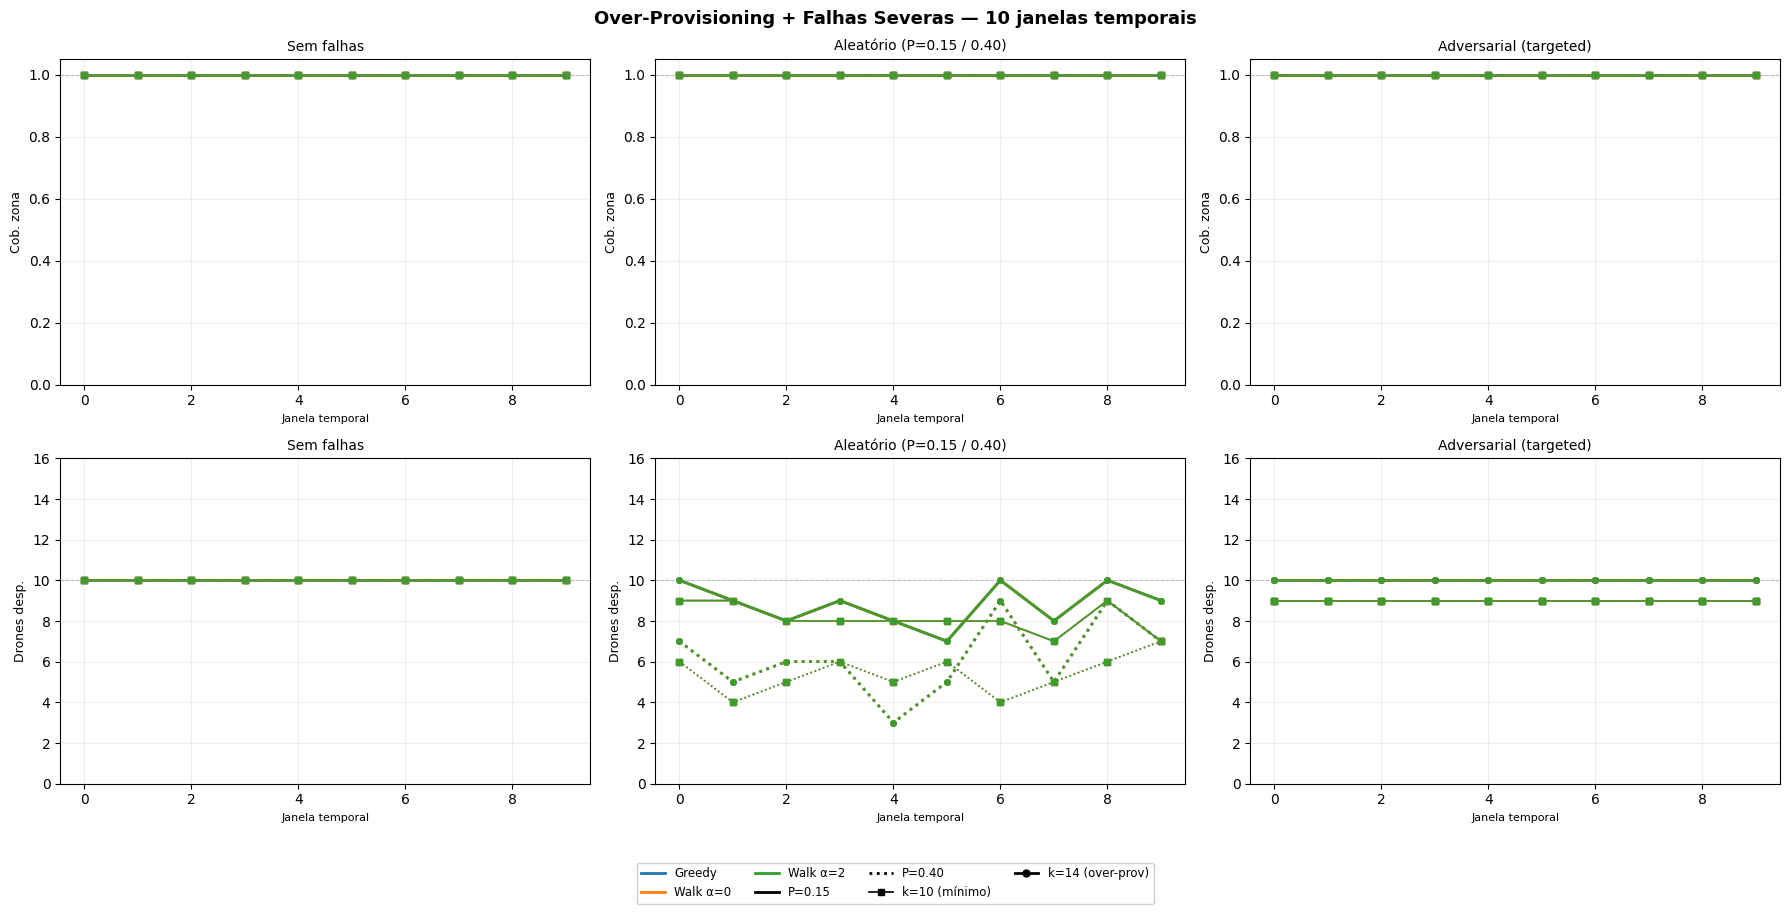

Figura salva em v7_tatico_overprov.png


In [18]:
# =============================================================
# Cell A5 — Visualização: cobertura e drones despachados por janela
# =============================================================

colors_da  = {"greedy": "C0", "walk_a0": "C1", "walk_a2": "C2"}
labels_da  = {"greedy": "Greedy", "walk_a0": "Walk α=0", "walk_a2": "Walk α=2"}
ls_sc      = {"k=10  P=0.15": "-",  "k=14  P=0.15": "--",
              "k=10  P=0.40": "-",  "k=14  P=0.40": "--"}
alpha_sc   = {"k=10  P=0.15": 1.0, "k=14  P=0.15": 1.0,
              "k=10  P=0.40": 1.0, "k=14  P=0.40": 1.0}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle("Over-Provisioning + Falhas Severas — 10 janelas temporais",
             fontsize=13, fontweight="bold")

plot_cfg = [
    # (row, col, fail_mode, metric_key, ylabel, ylim)
    (0, 0, "none",         "zone_cov",     "Cob. zona",      (0, 1.05)),
    (0, 1, "random_drone", "zone_cov",     "Cob. zona",      (0, 1.05)),
    (0, 2, "targeted_best","zone_cov",     "Cob. zona",      (0, 1.05)),
    (1, 0, "none",         "n_dispatched", "Drones desp.",   (0, 16)),
    (1, 1, "random_drone", "n_dispatched", "Drones desp.",   (0, 16)),
    (1, 2, "targeted_best","n_dispatched", "Drones desp.",   (0, 16)),
]
fail_titles = {"none": "Sem falhas", "random_drone": f"Aleatório (P=0.15 / 0.40)",
               "targeted_best": "Adversarial (targeted)"}

for row, col, fm, metric, ylabel, ylim in plot_cfg:
    ax = axes[row, col]
    ax.set_title(fail_titles[fm], fontsize=10)
    ts = list(range(T_WINDOWS))

    for sc in scenarios:
        lbl = sc["label"]
        for da in DISPATCH_ALGS_A:
            hist = all_results_A[(lbl, fm, da)]
            vals = [h[metric] for h in hist]
            color = colors_da[da]
            ls    = "-" if "P=0.15" in lbl else ":"
            lw    = 2.0 if "k=14" in lbl else 1.2
            label = f"{lbl} {labels_da[da]}" if col == 0 and row == 0 else None
            ax.plot(ts, vals, color=color, ls=ls, lw=lw,
                    marker="o" if "k=14" in lbl else "s", ms=4,
                    alpha=0.85, label=label)

    # Linhas de referência
    if metric == "zone_cov":
        ax.axhline(1.0, color="gray", lw=0.7, ls="--", alpha=0.5)
    if metric == "n_dispatched":
        ax.axhline(10, color="gray", lw=0.7, ls="--", alpha=0.5, label="k_opt=10")

    ax.set_ylim(ylim)
    ax.set_xlabel("Janela temporal", fontsize=8)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(alpha=0.2)

# Legenda unificada
from matplotlib.lines import Line2D
legend_els = (
    [Line2D([0],[0], color=c, lw=2, label=l) for c, l in
     zip(colors_da.values(), labels_da.values())] +
    [Line2D([0],[0], color="k", ls="-",  lw=2, label="P=0.15"),
     Line2D([0],[0], color="k", ls=":",  lw=2, label="P=0.40"),
     Line2D([0],[0], color="k", lw=1.2, marker="s", ms=5, label="k=10 (mínimo)"),
     Line2D([0],[0], color="k", lw=2.0, marker="o", ms=5, label="k=14 (over-prov)")]
)
fig.legend(handles=legend_els, loc="lower center", ncol=4,
           fontsize=8.5, framealpha=0.9, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES_DIR / "v7_tatico_overprov.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva em v7_tatico_overprov.png")